# State of the art: why the AMA was removed, the SMA debate and the heavy-tail instability

**Question:** Does a standardised formula that ignores the tail follow the risk of a bank whose true loss distribution is known, and is the internal model it replaced stable enough on ten years of data to have been worth keeping?


- **Level:** 3, State of the art
- **Prerequisites:** notebooks 02 to 06 of this topic
- **Reading time:** about 45 minutes

## Objectives

By the end of this notebook you can:

- say why the Basel Committee removed the Advanced Measurement Approach (AMA) and replaced it with the Standardised Measurement Approach (SMA), and what the academic critique of the SMA argued;
- put the two approaches side by side on the same committed histories of a synthetic bank, for four tail indices and two collection thresholds;
- read, in numbers, the claims that the SMA is insensitive to the risk profile and that a loss distribution estimated near a tail index of 1 is unstable;
- say what these synthetic results do and do not say about real banks.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The generator of case C17 and its estimators live in `data-pipeline/pipeline/cases/c17/`, which is not an installed package: this notebook loads those modules by path (importing the whole `pipeline` package would import every case and its heavy dependencies). The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
import types
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.oprisk import distributions, sma
from riskvalidation.validation import oprisk as oprisk_tests

for name in ('riskvalidation', 'numpy', 'scipy', 'matplotlib'):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

The data are the four variants of case C17, one per tail index of the synthetic bank (0.6, 0.8, 0.96 and 1.1), each with 16 numbers to compare: four cells (5 or 10 years of data, collection threshold EUR 10,000 or 20,000) of 1,000 independent simulated histories, estimated by the LDA ladder and by the SMA, against a known true 99.9% annual-loss quantile.

- **Files read:** `data/derived/C17/xi-0-6.json`, `xi-0-8.json`, `xi-0-96.json` and `xi-1-1.json`: `outputs.truth`, `outputs.cells[*].capital.lda_splice`, `outputs.cells[*].sma`, `outputs.bank` and `outputs.sma_response`, and `impact`.
- **Why the splice:** among the LDA rungs, the lognormal rungs are stable and badly biased (notebook 06), and the approximation and scenario rungs are variants of the tail model. The lognormal body with a generalised Pareto tail is the rung an operational-risk modeller would defend, so it is the one set against the SMA.
- **What is synthetic:** the generator is calibrated to published medians but invents the bank and its losses. Nothing below measures a real bank.

The next cell loads the documents and the generator.

In [2]:
# Load the four variant documents and the case's generator by path
ROOT = Path("../../..").resolve()
docs = {
    name: json.loads(
        (ROOT / "data" / "derived" / "C17" / (name + ".json")).read_text(encoding="utf-8")
    ) for name in ("xi-0-6", "xi-0-8", "xi-0-96", "xi-1-1")
}
sys.dont_write_bytecode = True
shell = types.ModuleType("c17")
shell.__path__ = [str(ROOT / "data-pipeline" / "pipeline" / "cases" / "c17")]
sys.modules["c17"] = shell
from c17 import generator, replicate

for name, doc in docs.items():
    print(
        name, "| true 99.9% quantile of the annual loss (EUR):",
        format(doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"], ",.0f"), "| baked by riskvalidation",
        doc["provenance"]["riskvalidation_version"]
    )

xi-0-6 | true 99.9% quantile of the annual loss (EUR): 33,897,000 | baked by riskvalidation 1.0.1
xi-0-8 | true 99.9% quantile of the annual loss (EUR): 163,483,000 | baked by riskvalidation 1.0.1
xi-0-96 | true 99.9% quantile of the annual loss (EUR): 634,865,452 | baked by riskvalidation 1.0.1
xi-1-1 | true 99.9% quantile of the annual loss (EUR): 2,148,602,460 | baked by riskvalidation 1.0.1


## Method

### Step 1: both approaches on the same histories

For each variant and cell the document holds, over the 1,000 histories, the ratio of the LDA splice capital to the true quantile (its median, its interquartile range over the truth, and the share of histories where the rung is defined) and the ratio of the SMA capital (the operational risk capital, ORC, of notebook 05) to the same true quantile. The next cell prints all 16 rows. The SMA is computed on every history, so it is always defined; the splice is defined only where its fit converges.

In [3]:
# Both approaches against the true quantile, for the 16 cells of the four variants
print(
    "%-8s %-10s | %-34s | %-30s" % (
        "", "", "LDA splice: defined, median, IQR / truth", "SMA: median, p25 - p75 over the truth"
    )
)
for name, doc in docs.items():
    for cell in doc["outputs"]["cells"]:
        splice = cell["capital"]["lda_splice"]
        ratio = cell["sma"]["orc_over_true_quantile"]
        print(
            "%-8s %-10s | %4d  %6.3f  %6.3f              | %6.3f   %6.3f - %6.3f" % (
                name, cell["id"], splice["n_defined"], splice["ratio_to_truth"]["median"], splice["iqr_over_truth"],
                ratio["median"], ratio["p25"], ratio["p75"]
            )
        )

                    | LDA splice: defined, median, IQR / truth | SMA: median, p25 - p75 over the truth
xi-0-6   y5-h10000  |  959   0.764   1.952              |  4.022    3.941 -  4.120
xi-0-6   y5-h20000  |  771   0.764   2.033              |  3.967    3.890 -  4.073
xi-0-6   y10-h10000 |  996   0.850   1.429              |  4.030    3.967 -  4.111
xi-0-6   y10-h20000 |  859   0.840   1.354              |  3.975    3.906 -  4.053
xi-0-8   y5-h10000  |  904   0.663   2.744              |  0.873    0.846 -  0.921
xi-0-8   y5-h20000  |  682   0.639   2.560              |  0.859    0.829 -  0.901
xi-0-8   y10-h10000 |  971   0.816   1.776              |  0.882    0.857 -  0.915
xi-0-8   y10-h20000 |  727   0.909   1.983              |  0.869    0.843 -  0.908
xi-0-96  y5-h10000  |  725   0.781   3.104              |  0.239    0.227 -  0.258
xi-0-96  y5-h20000  |  550   0.627   3.299              |  0.233    0.221 -  0.254
xi-0-96  y10-h10000 |  818   0.764   2.111              |  0.242   

### Step 2: the SMA in the engine, on one history per variant

The SMA ORC depends on the history only through the average annual loss and on the bank only through its business indicator. We regenerate the history behind each committed response block and call `sma_capital` with the bank's business indicator; the committed median over 1,000 histories of the cell with 10 years and a threshold of EUR 20,000 is printed beside it. The business indicator of the bank is the same in the four variants, so any difference in the SMA capital between variants comes from the losses only.

In [4]:
# The SMA capital of one regenerated history per variant, beside the committed median of the cell
print("%-8s %16s %12s %12s | %16s" % ("", "average annual loss", "ILM", "ORC", "committed median ORC"))
orc_single = {}
for name, doc in docs.items():
    block = doc["outputs"]["sma_response"]
    history = generator.draw_history(
        generator.variant(doc["outputs"]["tail_index"]), block["seed"], 10
    ).recorded(20_000.0)
    result = sma.sma_capital(doc["outputs"]["bank"]["business_indicator"]["bi_eur"], history.annual)
    orc_single[name] = result.orc
    cell = next(c for c in doc["outputs"]["cells"] if c["id"] == "y10-h20000")
    print(
        "%-8s %16s %12.4f %12s | %16s" % (
            name, format(history.annual.mean(), ",.0f"), result.ilm, format(result.orc, ",.0f"),
            format(cell["sma"]["orc_eur"]["median"], ",.0f")
        )
    )

         average annual loss          ILM          ORC | committed median ORC
xi-0-6          3,442,129       0.7355  132,388,684 |      134,743,278
xi-0-8          5,005,391       0.7953  143,154,295 |      142,003,392
xi-0-96         6,759,268       0.8544  153,800,481 |      151,571,436
xi-1-1          5,016,737       0.7957  143,227,478 |      165,036,744


The SMA reads the history only through its average. The case's estimator `replicate.estimate` also fits the loss distribution approach on the same history, so the next cell puts the two capitals of the regenerated history of each variant beside the true quantile.

In [5]:
# The SMA and the LDA splice capital of the same regenerated history of each variant, over the true quantile
for name, doc in docs.items():
    block = doc["outputs"]["sma_response"]
    variant_k = generator.variant(doc["outputs"]["tail_index"])
    bi_k = doc["outputs"]["bank"]["business_indicator"]["bi_eur"]
    history = generator.draw_history(variant_k, block["seed"], 10).recorded(20_000.0)
    try:
        fit = distributions.fit_splice(history.amounts, 20_000.0, 100_000.0)
        fit_text = "converged %s, body weight %.3f, tail index %.3f" % (fit.converged, fit.params[5], fit.params[3])
    except ValueError as error:
        fit_text = "refused: %s" % str(error)[:40]
    one = replicate.estimate(variant_k, block["seed"], 10, 20_000.0, bi_k, None, 20_000)
    truth_q = doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"]
    splice = one["lda_splice"]
    splice_text = "not defined" if np.isnan(splice) else "%s (%.3f of truth)" % (
        format(splice, ",.0f"), splice / truth_q
    )
    print("%-8s true %15s | SMA %15s (%.3f of truth) | LDA splice %s" %
          (name, format(truth_q, ",.0f"), format(one["orc"], ",.0f"), one["orc"] / truth_q, splice_text))
    print("%-8s splice fit of the history: %s" % ("", fit_text))

xi-0-6   true      33,897,000 | SMA     132,388,684 (3.906 of truth) | LDA splice 16,463,868 (0.486 of truth)
         splice fit of the history: converged True, body weight 0.937, tail index 0.472
xi-0-8   true     163,483,000 | SMA     143,154,295 (0.876 of truth) | LDA splice not defined
         splice fit of the history: converged False, body weight 1.000, tail index 0.686
xi-0-96  true     634,865,452 | SMA     153,800,481 (0.242 of truth) | LDA splice not defined
         splice fit of the history: converged False, body weight 1.000, tail index 1.029
xi-1-1   true   2,148,602,460 | SMA     143,227,478 (0.067 of truth) | LDA splice 953,379,755 (0.444 of truth)
         splice fit of the history: converged True, body weight 0.994, tail index 1.036


### Step 3: how much the capital moves when the risk profile does

Across the four variants the true 99.9% quantile of the annual loss is multiplied by a large factor, because the tail index goes from 0.6 to 1.1 with a similar frequency. A measure that follows the risk should follow that. The next cell prints, for the cell with 10 years and a threshold of EUR 20,000, the true quantile, the median SMA capital and the median LDA splice capital, and the factor between the largest and the smallest of each.

In [6]:
# True quantile, median SMA capital and median LDA splice capital across the four variants (10 years, threshold EUR
# 20,000)
rows = []
for name, doc in docs.items():
    cell = next(c for c in doc["outputs"]["cells"] if c["id"] == "y10-h20000")
    truth_q = doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"]
    rows.append(
        (name, truth_q, cell["sma"]["orc_eur"]["median"], cell["capital"]["lda_splice"]["capital_eur"]["median"])
    )
    print(
        "%-8s truth %15s | SMA %15s | LDA splice %15s" % (
            name, format(truth_q, ",.0f"), format(rows[-1][2], ",.0f"), format(rows[-1][3], ",.0f")
        )
    )
for label, column in (("true quantile", 1), ("SMA", 2), ("LDA splice", 3)):
    values = [r[column] for r in rows]
    print("%-24s largest / smallest: %.1f" % (label, max(values) / min(values)))

xi-0-6   truth      33,897,000 | SMA     134,743,278 | LDA splice      28,481,721
xi-0-8   truth     163,483,000 | SMA     142,003,392 | LDA splice     148,533,735
xi-0-96  truth     634,865,452 | SMA     151,571,436 | LDA splice     589,526,564
xi-1-1   truth   2,148,602,460 | SMA     165,036,744 | LDA splice   1,558,118,060
true quantile            largest / smallest: 63.4
SMA                      largest / smallest: 1.2
LDA splice               largest / smallest: 54.7


The next cell draws the capital of each approach across the four tail indices, on a logarithmic axis: the true 99.9% quantile, the median SMA capital and the median LDA splice capital, from the table printed above.

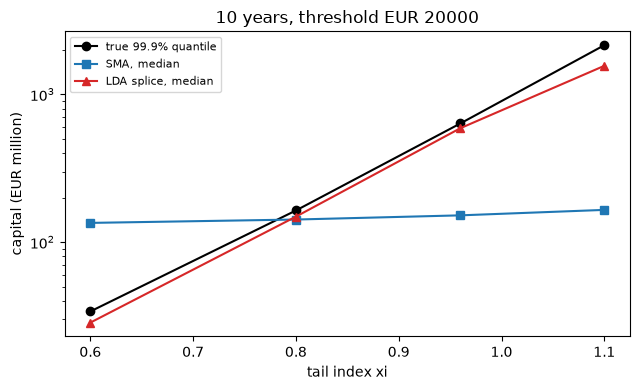

In [7]:
# Draw the true quantile, the median SMA capital and the median LDA splice capital across the tail indices
xis = [doc["outputs"]["tail_index"] for doc in docs.values()]
fig, ax = plt.subplots(figsize=(6.5, 4.0))
ax.semilogy(xis, [r[1] / 1e6 for r in rows], "ko-", label="true 99.9% quantile")
ax.semilogy(xis, [r[2] / 1e6 for r in rows], "s-", color="tab:blue", label="SMA, median")
ax.semilogy(xis, [r[3] / 1e6 for r in rows], "^-", color="tab:red", label="LDA splice, median")
ax.set_xlabel("tail index xi")
ax.set_ylabel("capital (EUR million)")
ax.set_title("10 years, threshold EUR 20000")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The black line is the risk: it climbs from EUR 33,897,000 at tail index 0.6 to EUR 2,148,602,460 at 1.1, a factor of 63.4. The red line follows it, a factor of 54.7, while the blue SMA line is almost flat, EUR 134,743,278 to EUR 165,036,744, a factor of 1.2. A bank whose tail doubles in weight sees no change in its standardised capital; that is the risk insensitivity the critics describe. The figure shows medians only, and says nothing about the spread of the red line, which the later figure draws.

### Step 4: the tail index fitted on one history near 1

The LDA needs the tail index, and near 1 it is hard to learn. On the history of each variant we fit the generalised Pareto at the four thresholds of notebook 02 with `tail_index_profile` and print the estimates and their standard errors. The true index of the last variant, 1.1, means an infinite mean; whether the fitted one stays above or below 1 is up to the sample.

In [8]:
# Fit the tail-index profile on the regenerated history of each variant
thresholds = 20_000.0 * np.array([1.0, 2.0, 4.0, 8.0])
profiles = {}
for name, doc in docs.items():
    block = doc["outputs"]["sma_response"]
    history = generator.draw_history(
        generator.variant(doc["outputs"]["tail_index"]), block["seed"], 10
    ).recorded(20_000.0)
    profiles[name] = distributions.tail_index_profile(history.amounts, thresholds)
    xi_hat, xi_se = profiles[name].xi, profiles[name].xi_se
    print("%-8s true xi %-5s | xi_hat %s | se %s | estimates at or above 1: %d" %
          (name, doc["outputs"]["tail_index"], np.round(xi_hat, 3), np.round(xi_se, 3), int((xi_hat >= 1).sum())))

xi-0-6   true xi 0.6   | xi_hat [0.588 0.468 0.501 0.378] | se [0.081 0.099 0.154 0.178] | estimates at or above 1: 0
xi-0-8   true xi 0.8   | xi_hat [0.936 0.845 0.745 0.681] | se [0.093 0.124 0.166 0.239] | estimates at or above 1: 0
xi-0-96  true xi 0.96  | xi_hat [1.02  0.963 1.029 0.87 ] | se [0.099 0.129 0.198 0.257] | estimates at or above 1: 2
xi-1-1   true xi 1.1   | xi_hat [0.956 0.947 1.04  0.89 ] | se [0.095 0.135 0.211 0.328] | estimates at or above 1: 1


The next cell draws those fitted indices with two-standard-error bars against the true value of each variant and the line at 1, where the mean of the severity stops being finite.

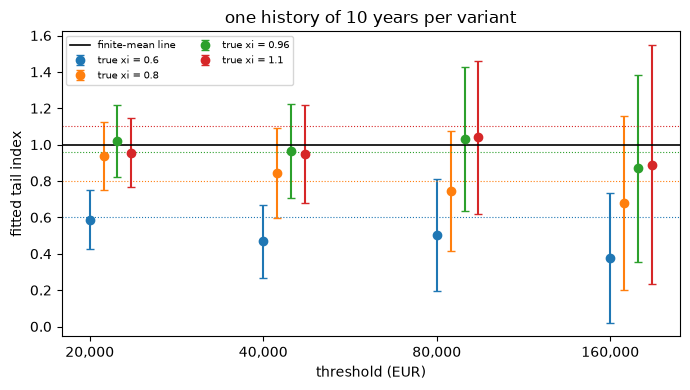

In [9]:
# Draw the fitted tail indices of one history per variant against the true index and the finite-mean line
palette = ["tab:blue", "tab:orange", "tab:green", "tab:red"]
fig, ax = plt.subplots(figsize=(7.0, 4.0))
for k, (name, doc) in enumerate(docs.items()):
    true_xi = doc["outputs"]["tail_index"]
    fit = profiles[name]
    ax.errorbar(
        np.arange(4) + 0.08 * k, fit.xi, yerr=2 * fit.xi_se, fmt="o", color=palette[k], capsize=3,
        label="true xi = %s" % true_xi
    )
    ax.axhline(true_xi, color=palette[k], linestyle=":", linewidth=0.8)
ax.axhline(1.0, color="black", linewidth=1.2, label="finite-mean line")
ax.set_xticks(range(4))
ax.set_xticklabels([format(int(u), ",") for u in thresholds])
ax.set_xlabel("threshold (EUR)")
ax.set_ylabel("fitted tail index")
ax.set_title("one history of 10 years per variant")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

The two heavy variants are the trouble: for a true index of 0.96 two of the four fitted values sit at or above the black line, and for a true 1.1 only one does, with the other three at 0.956, 0.947 and 0.89 telling the modeller the mean is finite when it is not. The bars are wide, 0.095 to 0.328 in standard error, so the data cannot tell 0.96 from 1.1. This is the mechanism behind the instability of the next figure. It uses one history per variant; other histories would cross the line in other places.

## State of the art

**Why the AMA was removed.** In its consultative document of 4 March 2016 the Basel Committee wrote that its review of banks' operational risk modelling practices and capital outcomes had revealed that the inherent complexity of the Advanced Measurement Approach (AMA), and the lack of comparability arising from a wide range of internal modelling practices, had exacerbated variability in risk-weighted asset calculations and eroded confidence in risk-weighted capital ratios. It proposed to remove the AMA and to base the framework on a single non-model-based method, the Standardised Measurement Approach (BCBS, 2016). The final reforms are in Basel III: Finalising post-crisis reforms (BCBS, 2017), and the rules of the standardised approach are the OPE25 chapter of the Basel Framework used in notebook 05.

**The critique.** Peters, Shevchenko, Hassani and Chapelle (2016) discuss what they call the weaknesses and pitfalls of the SMA, among them instability, risk insensitivity and super-additivity, and advocate keeping the AMA internal-model framework with standardisation recommendations. Mignola, Ugoccioni and Cope (2016) published comments on the Committee's proposal in the same issue of the journal.

**What the loss distribution approach (LDA) is.** The compound sum of notebook 01 with the building blocks of notebook 02 (Chavez-Demoulin, Embrechts and Neslehova, 2006), computed exactly by the recursion of Panjer (1981) or the fast Fourier transform and checked against Shevchenko (2010) in notebook 03, approximated in closed form in notebook 04, and combined with expert scenarios by Bayesian credibility in notebook 05 (Shevchenko and Wuthrich, 2006). For the closed-form approximation the research behind this case summarises Degen (2010) as analysing it by tail index and finding a problematic zone near a tail index of 1; the primary text was not re-read for this notebook.

**Where the research reads more than the sources say.** The research behind the case presents the heavy-tail instability as a teaching case, built on one illustrative calibration of the Basel Committee's 2008 medians (a tail index near 0.96, with caveats), and reads it as the kind of instability that motivated the move away from the AMA. That reading is the research's own: the Committee's document gives complexity and comparability as its reasons. This notebook does not settle the question for real banks. What it adds is a measurement on a generator whose truth is known: the next two cells put the two claims of the critique, risk insensitivity of the SMA and instability of the LDA, to the committed numbers.

The committed tables below summarise 1,000 histories per cell; the state of the art can also be run. The next cell estimates the LDA splice and the SMA on 30 fresh independent histories of each variant (seeds from 9,500,000, outside every committed range, about a minute) and prints how many each rung could fit and the median and spread of its capital over the truth.

In [10]:
# Estimate the LDA splice and the SMA on 30 fresh independent histories of each variant
fresh = {}
for k, (name, doc) in enumerate(docs.items()):
    variant_k = generator.variant(doc["outputs"]["tail_index"])
    bi_k = doc["outputs"]["bank"]["business_indicator"]["bi_eur"]
    seeds = [9_500_000 + 1000 * k + j for j in range(30)]
    histories = [generator.draw_history(variant_k, s, 10).recorded(20_000.0) for s in seeds]
    orc = np.array([sma.sma_capital(bi_k, h.annual).orc for h in histories])
    runs = [replicate.estimate(variant_k, s, 10, 20_000.0, bi_k, None, 20_000) for s in seeds]
    keep = ("lda_splice", "sla_mean_adjusted", "sla_cvm", "sla_obre")
    fresh[name] = {rung: np.array([r[rung] for r in runs], dtype=float) for rung in keep}
    fresh[name]["orc"] = orc
    truth_q = doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"]
    for rung, label in (("lda_splice", "LDA splice"), ("orc", "SMA")):
        ratios = fresh[name][rung][np.isfinite(fresh[name][rung])] / truth_q
        q25, q50, q75 = np.percentile(ratios, [25, 50, 75])
        print(
            "%-8s %-10s defined %2d | median / truth %6.3f | IQR / truth %6.3f" % (
                name, label, ratios.size, q50, q75 - q25
            )
        )

xi-0-6   LDA splice defined 25 | median / truth  1.130 | IQR / truth  1.024
xi-0-6   SMA        defined 30 | median / truth  3.986 | IQR / truth  0.159
xi-0-8   LDA splice defined 26 | median / truth  0.738 | IQR / truth  1.409
xi-0-8   SMA        defined 30 | median / truth  0.868 | IQR / truth  0.055
xi-0-96  LDA splice defined 18 | median / truth  0.483 | IQR / truth  1.309
xi-0-96  SMA        defined 30 | median / truth  0.234 | IQR / truth  0.034
xi-1-1   LDA splice defined 15 | median / truth  0.672 | IQR / truth  4.840
xi-1-1   SMA        defined 30 | median / truth  0.073 | IQR / truth  0.009


The engine's `oprisk.capital_stability` turns those fresh capitals into the dispersion and the bias that the case's lights use. The next cell runs it for the SMA and for the splice in each variant.

In [11]:
# Run the engine's capital-stability test on the fresh capitals of the SMA and of the LDA splice
print("%-8s %-10s %11s %9s %8s" % ("", "", "dispersion", "bias", "light"))
for name, doc in docs.items():
    truth_q = doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"]
    for rung, label in (("lda_splice", "LDA splice"), ("orc", "SMA")):
        capitals = fresh[name][rung][np.isfinite(fresh[name][rung])]
        result = oprisk_tests.capital_stability(capitals, truth_q, model_id=rung)
        print("%-8s %-10s %11.3f %+9.3f %8s" % (name, label, result.metric, result.statistic, result.light.value))

                     dispersion      bias    light
xi-0-6   LDA splice       1.024    +0.130      red
xi-0-6   SMA              0.159    +2.986      red
xi-0-8   LDA splice       1.409    -0.262      red
xi-0-8   SMA              0.055    -0.132    amber
xi-0-96  LDA splice       1.309    -0.517      red
xi-0-96  SMA              0.034    -0.766      red
xi-1-1   LDA splice       4.840    -0.328      red
xi-1-1   SMA              0.009    -0.927      red


The next cell draws the 30 fresh capitals of each variant over the true quantile as box plots, for the SMA and for the LDA splice, on a logarithmic axis.

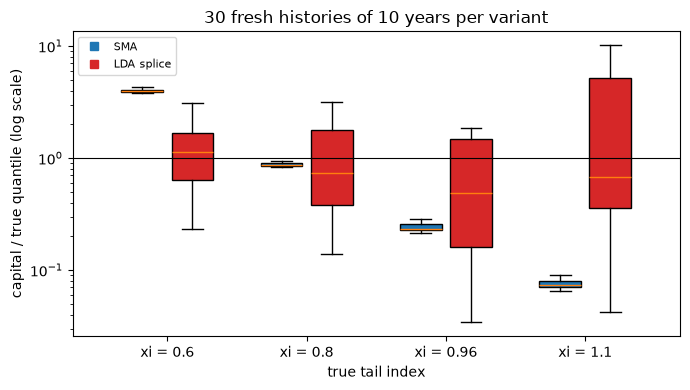

In [12]:
# Draw the fresh capitals over the true quantile, SMA and LDA splice, one pair of boxes per variant
fig, ax = plt.subplots(figsize=(7.0, 4.0))
colors = {"orc": "tab:blue", "lda_splice": "tab:red"}
for k, (name, doc) in enumerate(docs.items()):
    truth_q = doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"]
    for offset, rung in ((-0.18, "orc"), (0.18, "lda_splice")):
        ratios = fresh[name][rung][np.isfinite(fresh[name][rung])] / truth_q
        box = ax.boxplot(ratios, positions=[k + offset], widths=0.3, patch_artist=True, showfliers=False)
        box["boxes"][0].set_facecolor(colors[rung])
ax.set_yscale("log")
ax.axhline(1.0, color="black", linewidth=0.8)
ax.set_xticks(range(4))
ax.set_xticklabels(["xi = %s" % doc["outputs"]["tail_index"] for doc in docs.values()])
ax.plot([], [], "s", color=colors["orc"], label="SMA")
ax.plot([], [], "s", color=colors["lda_splice"], label="LDA splice")
ax.set_xlabel("true tail index")
ax.set_ylabel("capital / true quantile (log scale)")
ax.set_title("30 fresh histories of 10 years per variant")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The boxes repeat the committed finding on fresh histories. The SMA box is a thin sliver, with an interquartile range of 0.159 down to 0.009 of the truth, but it sits at 3.986 times the truth at tail index 0.6 and at 0.073 at 1.1: stable, and wrong in opposite directions. The LDA splice boxes are tall, 1.024 to 4.840 in interquartile range, and the splice could be fitted on only 25, 26, 18 and 15 of the 30 histories, so where it exists it is unreliable and often it does not exist at all, as the one-history table showed with its undefined entries. The engine's test paints every box red except the SMA at 0.8. Thirty histories show the pattern, not its size.

The last two cells go back to the committed numbers, 1,000 histories per cell, to put the two claims of the literature to a size no 30-history run can reach: the SMA follows the risk very little, and the LDA capital is unstable.

In [13]:
# Put two claims of the literature to the committed numbers of the cell with 10 years and a threshold of EUR 20,000
spread_truth, spread_sma, spread_lda, spread_lda_iqr = [], [], [], []
for name, doc in docs.items():
    cell = next(c for c in doc["outputs"]["cells"] if c["id"] == "y10-h20000")
    spread_truth.append(doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"])
    spread_sma.append(cell["sma"]["orc_eur"]["median"])
    spread_lda.append(cell["capital"]["lda_splice"]["ratio_to_truth"]["median"])
    spread_lda_iqr.append(cell["capital"]["lda_splice"]["iqr_over_truth"])
print(
    "risk insensitivity: the SMA moves by a factor %.2f while the true quantile moves by %.1f" % (
        max(spread_sma) / min(spread_sma), max(spread_truth) / min(spread_truth)
    )
)
print("instability: the interquartile range of the LDA splice over the truth is %s" % np.round(spread_lda_iqr, 2))
print(
    "SMA / truth by variant:", np.round(np.array(spread_sma) / np.array(spread_truth), 3),
    "| median LDA splice / truth:", np.round(spread_lda, 3)
)

risk insensitivity: the SMA moves by a factor 1.22 while the true quantile moves by 63.4
instability: the interquartile range of the LDA splice over the truth is [1.35 1.98 2.23 2.32]
SMA / truth by variant: [3.975 0.869 0.239 0.077] | median LDA splice / truth: [0.84  0.909 0.929 0.725]


The next cell draws the ratio of each capital to the true quantile, with the 25% to 75% band of the LDA splice over 1,000 histories, for the four tail indices. A ratio of 1 is a capital equal to the truth.

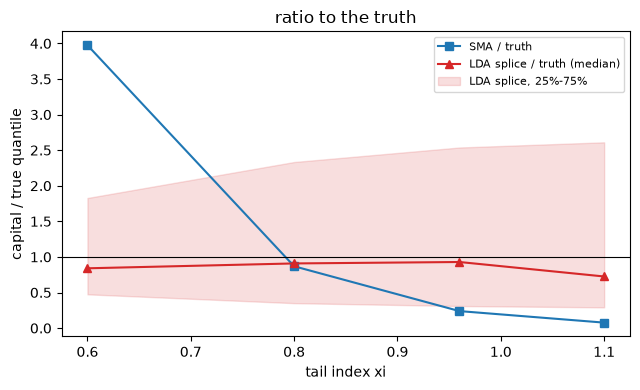

In [14]:
# Draw the ratio of the SMA and of the LDA splice to the true quantile, with the interquartile band of the splice
cells = {name: next(c for c in doc["outputs"]["cells"] if c["id"] == "y10-h20000") for name, doc in docs.items()}
truths = np.array([doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"] for doc in docs.values()])
splice = {
    key: np.array(
        [cells[n]["capital"]["lda_splice"]["capital_eur"][key] for n in docs]
    ) for key in ("p25", "median", "p75")
}
sma_median = np.array([cells[n]["sma"]["orc_eur"]["median"] for n in docs])
fig, ax = plt.subplots(figsize=(6.5, 4.0))
ax.plot(xis, sma_median / truths, "s-", color="tab:blue", label="SMA / truth")
ax.plot(xis, splice["median"] / truths, "^-", color="tab:red", label="LDA splice / truth (median)")
ax.fill_between(
    xis, splice["p25"] / truths, splice["p75"] / truths, color="tab:red", alpha=0.15, label="LDA splice, 25%-75%"
)
ax.axhline(1.0, color="black", linewidth=0.8)
ax.set_xlabel("tail index xi")
ax.set_ylabel("capital / true quantile")
ax.set_title("ratio to the truth")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

The blue SMA line falls from 3.975 times the truth at tail index 0.6 to 0.077 at 1.1: it overcharges a light-tailed bank and undercharges a heavy-tailed one, by construction, because it never looks at the tail. The red median stays close to 1, 0.84 to 0.93 times the truth and 0.725 at the end, but its shaded band is as wide as the truth itself, an interquartile range of 1.35, 1.98, 2.23 and 2.32. Neither estimator is good: one is precise and wrong, the other right on average and unreliable for any one bank. The figure is a measurement on a generator, not a verdict on the Committee's decision.

### The robust severity rungs (M-32)

The instability above comes from the severity fit: a maximum-likelihood GPD reacts to every large loss, and one more or one less
in ten years moves the 99.9 % quantile by a factor. Opdyke and Cavallo (2012) proposed robust estimators for the severity of
operational losses, the optimally bias-robust estimator of Hampel, Ronchetti, Rousseeuw and Stahel (1986, section 4.2), which bounds
the influence any single loss can have, and the minimum Cramer-von Mises distance, which fits the whole distribution function
rather than the likelihood of each point, together with the single loss approximation corrected for the mean. The engine's
`riskvalidation.oprisk.robust` implements the three, and the product's C17 ladder carries them as four rungs: the GPD by maximum
likelihood, by Cramer-von Mises and by the optimally bias-robust estimator at 95 % efficiency, each through the mean-adjusted SLA,
and a Cramer-von Mises lognormal as a misspecified control. The mean-adjusted form is the one Degen (2010) states and arXiv
1607.02319 repeats; the primary text of Opdyke and Cavallo was not read, so the rungs carry the status `SECONDARY_SOURCE`.

The fresh histories of the cell above already ran every rung, because `replicate.estimate` returns them all; the next cell reads
the three GPD rungs beside the LDA splice, as capital over the true quantile of each variant.

In [ ]:
# The S-3 rungs beside the LDA splice on the same 30 fresh histories: the share defined, the median and the spread
ROBUST = ("lda_splice", "sla_mean_adjusted", "sla_cvm", "sla_obre")
quartiles = {}
defined_label = "defined"
for name, doc in docs.items():
    truth_q = doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"]
    for rung in ROBUST:
        ratios = fresh[name][rung][np.isfinite(fresh[name][rung])] / truth_q
        quartiles[(name, rung)] = np.percentile(ratios, [25, 50, 75])
        q25, q50, q75 = quartiles[(name, rung)]
        print(f"{name:8s} {rung:18s} {defined_label} {ratios.size:2d} | median {q50:6.3f} | IQR {q75 - q25:6.3f}")


A rung that refuses a history is not drawn: the SLA needs a finite mean, so when the fitted tail index reaches 1 the rung
returns nothing, which is why the defined counts fall at tail index 1.1 to between 10 and 13 of 30 against 15 for the splice. The
figure draws each median as a point and its interquartile range as a bar, on a log scale where the truth is the black line.

In [ ]:
# Draw the median of capital / truth of each rung and variant, with its interquartile range as a bar
fig, ax = plt.subplots(figsize=(9.0, 4.0))
offsets = np.linspace(-0.27, 0.27, len(ROBUST))
for offset, rung in zip(offsets, ROBUST):
    x = np.arange(len(docs)) + offset
    q = np.array([quartiles[(name, rung)] for name in docs])
    ax.vlines(x, q[:, 0], q[:, 2], linewidth=6, alpha=0.35)
    ax.plot(x, q[:, 1], "o", label=rung)
ax.set_yscale("log")
ax.axhline(1.0, color="black", linewidth=0.8)
ax.set_xticks(range(len(docs)))
ax.set_xticklabels(["xi = %s" % doc["outputs"]["tail_index"] for doc in docs.values()])
ax.set_xlabel("true tail index")
ax.set_ylabel("capital / true quantile (log scale)")
ax.set_title("Robust severity fits against the splice, 30 fresh histories per variant")
ax.legend(fontsize=8, ncol=2)
fig.tight_layout()
plt.show()


At tail index 0.6 the splice is the tightest (an interquartile range of 1.024 of the truth) and the robust fits gain
nothing; the mean-adjusted SLA and the optimally bias-robust fit sit nearer the truth (1.056 and 1.069) but spread more. At 0.8 and
0.96 the order turns: the Cramer-von Mises fit has a median of 0.862 and 0.555 with a range of 1.065 and 0.369, the optimally
bias-robust fit 0.832 and 0.899, while the splice drifts down to 0.483 at 0.96 with a range of 1.309. At 1.1, where the mean is
infinite, every SLA rung collapses to about a fifth of the truth with a narrow range, a stable and wrong answer, and the splice
stays near 0.67 with a range of almost five times the truth. Robustness buys tightness where the tail is heavy but finite, and
nothing where the model's assumption of a finite mean is broken.

## Results

**Answer:** Neither critique is refuted on this synthetic bank. The committed SMA moves by a factor of 1.22 while the true 99.9% quantile moves by 63.4, and it is 3.975 times the truth at tail index 0.6 and 0.077 times at 1.1; on 30 fresh histories per variant it is stable (dispersion 0.159 down to 0.009) but biased from +2.986 to -0.927. The LDA splice follows the risk on average, yet its interquartile range over the truth is 1.35, 1.98, 2.23 and 2.32 on the committed histories and 4.840 at the heaviest tail on the fresh ones, and the tail index fitted near 1 crosses the finite-mean line by sampling alone.

- **Side by side.** On the 16 cells, the SMA is tight and the LDA splice is wide. The interquartile range of the SMA over the truth is between 0.015 and 0.183, while the splice has a range between 1.35 and 3.30 times the truth. The splice is defined on 128 to 996 of the 1,000 histories, fewest at tail index 1.1 with a threshold of EUR 10,000 over 10 years.
- **Risk insensitivity.** With 10 years and a threshold of EUR 20,000 the true 99.9% quantile grows by a factor of 63.4 between tail indices 0.6 and 1.1 (EUR 33.9 million to EUR 2.15 billion), the median LDA splice by 54.7, and the median SMA by only 1.2 (EUR 134.7 million to EUR 165.0 million). The SMA is 3.98 times the truth at tail index 0.6, 0.87 at 0.8, 0.24 at 0.96 and 0.077 at 1.1: it overstates a light tail and understates a heavy one. The SMA is not calibrated to the 99.9% quantile of any bank (the document says so), so these ratios are a comparison, not an error of the SMA.
- **Instability.** The interquartile range of the splice over the truth is 1.35, 1.98, 2.23 and 2.32 across the four tail indices: for a bank with ten years of data, the LDA capital of two banks of the same true risk differs by about as much as the risk itself. The medians are close to the truth (0.84, 0.91, 0.93 and 0.73 times it), so the LDA is not far off on average and is far off on any one history.
- **Near 1.** On a single regenerated history the fitted tail index at four thresholds is 1.02, 0.96, 1.03 and 0.87 where the truth is 0.96, so two of four estimates cross the finite-mean line, and 0.96, 0.95, 1.04 and 0.89 where the truth is 1.1, so three of four estimates say the mean is finite when it is not. Standard errors of 0.10 to 0.33 explain why.
- **One history.** The SMA of the single regenerated history is close to the committed median at three variants (EUR 132.4 million against 134.7 million, EUR 143.2 million against 142.0 million, EUR 153.8 million against 151.6 million) and 13% below it at tail index 1.1 (EUR 143.2 million against 165.0 million), where a few large losses move the average of ten years.
- **What this says about real banks.** Nothing directly: the bank is synthetic and the generator is the only truth. It says that the two claims of the critique, an SMA that follows the risk very little and an LDA that is unstable at the data lengths and tail indices the Basel statistics suggest, hold for the estimators and gates of this case, and it measures both with a known truth.

What this notebook does not show: how the dispersion of the LDA capital depends on the length of history and on the tail index, measured with the engine's stability test on independent histories (the level 4 notebook).

The robust severity rungs (M-32) narrow the capital where the tail is heavy but its mean finite: at tail index 0.96 the
Cramer-von Mises fit has an interquartile range of 0.369 of the truth against 1.309 for the splice, while at 0.6 the splice stays the
tightest and at 1.1 every SLA rung collapses to about a fifth of the truth.

## Summary

- The Basel Committee removed the AMA for its complexity and the lack of comparability of internal models, and replaced it with the non-model-based SMA; critics argued that the SMA is risk-insensitive and unstable.
- On a synthetic bank with a known truth, the SMA changes by a factor of 1.2 while the true quantile changes by 63, and it is 3.98 times the truth at a light tail and 0.077 at a heavy one.
- The median of the LDA splice is near the truth but its interquartile range is 1.35 to 2.32 times the truth with ten years of data; the fitted tail index near 1 crosses the finite-mean line by sampling alone.
- These are measurements on a generator, not statements about real banks, and the instability argument as a reason for the Basel decision is the research's reading, not the Committee's.

**What to try next.** Open the `xi-0-96.json` document and print the cells with 5 years against 10 years to see the dispersion of the splice grow. Then continue with notebook 08, which measures that dispersion with the engine's stability test.

- The robust severity fits of S-3 (M-32) tighten the capital at tail indices 0.8 and 0.96, not at 0.6, and give a stable, wrong capital when the mean is infinite.

## References

- BCBS (2016), Standardised Measurement Approach for operational risk, consultative document, 4 March 2016. https://www.bis.org/bcbs/publ/d355.htm
- BCBS (2017), Basel III: Finalising post-crisis reforms. https://www.bis.org/bcbs/publ/d424.htm
- BCBS, Basel Framework OPE25, Calculation of RWA for operational risk. https://www.bis.org/basel_framework/chapter/OPE/25.htm
- Peters, G. W., Shevchenko, P. V., Hassani, B. and Chapelle, A. (2016), Should the advanced measurement approach be replaced with the standardized measurement approach for operational risk?, Journal of Operational Risk 11(3). https://arxiv.org/abs/1607.02319
- Mignola, G., Ugoccioni, R. and Cope, E. (2016), Comments on the Basel Committee on Banking Supervision proposal for a new standardized approach for operational risk, Journal of Operational Risk 11(3), 51-69. https://doi.org/10.21314/JOP.2016.184
- Degen, M. (2010), The calculation of minimum regulatory capital using single-loss approximations, Journal of Operational Risk 5(4), 3-17. https://doi.org/10.21314/JOP.2010.084
- Chavez-Demoulin, V., Embrechts, P. and Neslehova, J. (2006), Quantitative models for operational risk: extremes, dependence and aggregation, Journal of Banking and Finance 30(10), 2635-2658. https://doi.org/10.1016/j.jbankfin.2005.11.008

- Opdyke, J. D. and Cavallo, A. (2012), Estimating operational risk capital: the challenges of truncation, the hazards of maximum likelihood estimation, and the promise of robust statistics, Journal of Operational Risk 7(3) (primary text not read; the estimators follow their textbook definitions)
- Hampel, F. R., Ronchetti, E. M., Rousseeuw, P. J. and Stahel, W. A. (1986), Robust Statistics: The Approach Based on Influence Functions, Wiley, section 4.2.
- Degen, M. (2010), the second-order term of the single loss approximation, as stated in arXiv 1607.02319, https://arxiv.org/abs/1607.02319